# Fragmentation Explainability Analysis

explainability of fragmentation DAGs by chemical class.


In [41]:
import gc
import pickle
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

DATA_ROOT = Path("../data")

## 1. Explainable Masses by Chemical Class (Fragmentation DAG Coverage)

Uses `mol_stats_df` from `data/frag/nps_nist23_d3/`, which records per-molecule fragmentation DAG statistics.

**Key metric – weighted recall (`wrecall_10ppm_h4`)**: fraction of total spectral peak intensity whose *m/z* is within 10 ppm of at least one formula mass in the fragmentation DAG (allowing up to 4 H-shifts).  A low value means the DAG is missing fragments needed to explain the observed spectrum — i.e. "low explainability".

In [42]:
# Load frag DAG stats and join with ClassyFire taxonomy
mol_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/mol_stats_df.pkl")

cf_df = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")
cf_cols = ["mol_id", "kingdom", "superklass", "klass", "subklass"]

frag_cf = mol_stats_df.merge(cf_df[cf_cols], on="mol_id", how="left")
print(f"mol_stats_df rows: {len(mol_stats_df):,}  |  after CF join: {len(frag_cf):,}")
print(f"CF annotation coverage: {frag_cf['superklass'].notna().mean():.1%}")

WRECALL_COL = "wrecall_10ppm_h4"  # primary explainability metric
print(f"\nOverall {WRECALL_COL} stats:")
print(frag_cf[WRECALL_COL].describe().round(3))

del mol_stats_df
gc.collect()

mol_stats_df rows: 1,486  |  after CF join: 1,486
CF annotation coverage: 100.0%

Overall wrecall_10ppm_h4 stats:
count    1486.000
mean        0.894
std         0.109
min         0.105
25%         0.849
50%         0.932
75%         0.970
max         1.000
Name: wrecall_10ppm_h4, dtype: float64


0

Weighted recall by superclass:
                                         median_wrecall  mean_wrecall  n_mols
superklass                                                                   
alkaloids and derivatives                         0.974         0.934      16
organometallic compounds                          0.960         0.960       1
organohalogen compounds                           0.952         0.947      10
nucleosides, nucleotides, and analogues           0.948         0.960       3
organic nitrogen compounds                        0.946         0.920      33
hydrocarbons                                      0.945         0.887       4
phenylpropanoids and polyketides                  0.942         0.869      43
organic acids and derivatives                     0.940         0.902      98
organic oxygen compounds                          0.939         0.892      43
benzenoids                                        0.939         0.896     121
acetylides                       

/tmp/ipykernel_1289096/1367276464.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups_super, labels=labels_super, patch_artist=True, medianprops=dict(color="black", linewidth=2))


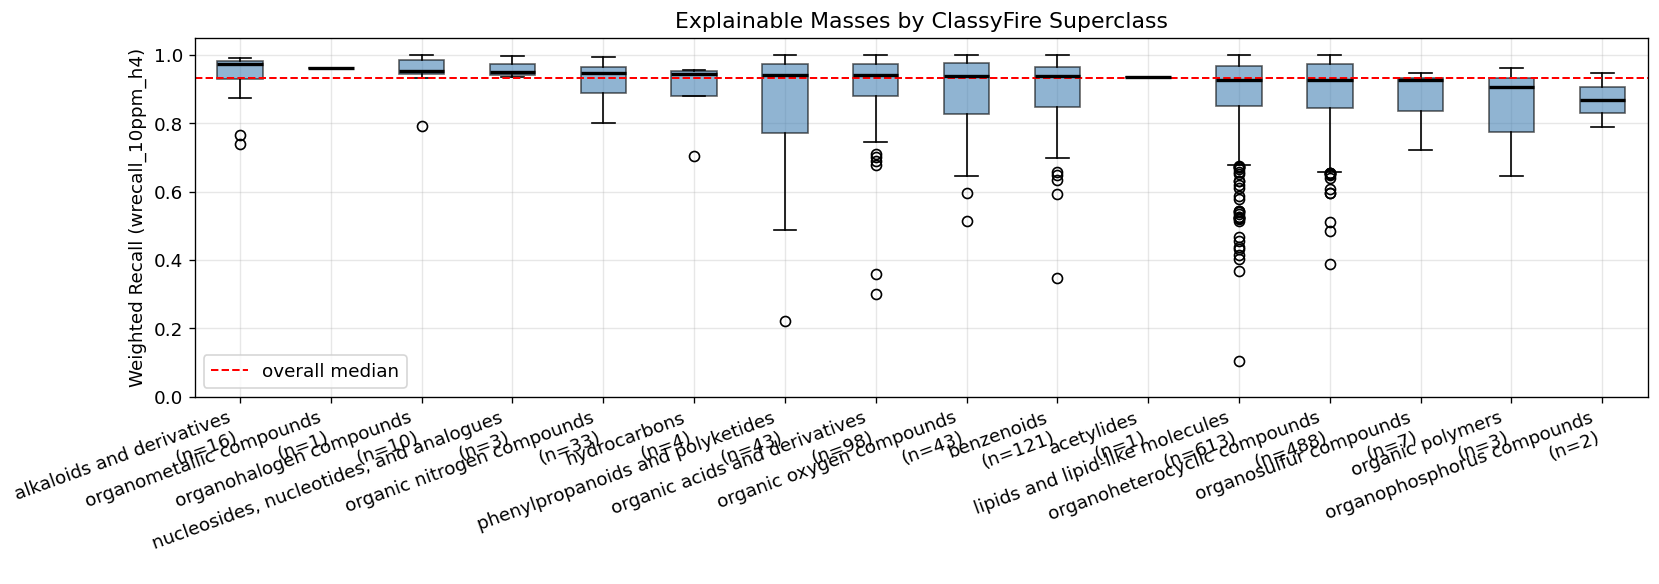

In [43]:
# --- Weighted recall by ClassyFire Superclass ---
df_super = frag_cf.dropna(subset=["superklass"])
super_order = (
    df_super.groupby("superklass")[WRECALL_COL]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

super_stats = (
    df_super.groupby("superklass")[WRECALL_COL]
    .agg(["median", "mean", "count"])
    .reindex(super_order)
    .round(3)
)
super_stats.columns = ["median_wrecall", "mean_wrecall", "n_mols"]
print("Weighted recall by superclass:")
print(super_stats.to_string())

groups_super = [df_super[df_super["superklass"] == s][WRECALL_COL].dropna().values for s in super_order]
labels_super = [f"{s}\n(n={len(g)})" for s, g in zip(super_order, groups_super)]

fig, ax = plt.subplots(figsize=(14, 5))
bp = ax.boxplot(groups_super, labels=labels_super, patch_artist=True, medianprops=dict(color="black", linewidth=2))
for patch in bp["boxes"]:
    patch.set_facecolor("steelblue")
    patch.set_alpha(0.6)
ax.axhline(frag_cf[WRECALL_COL].median(), color="red", linestyle="--", linewidth=1.2, label="overall median")
ax.set_ylabel(f"Weighted Recall ({WRECALL_COL})")
ax.set_title("Explainable Masses by ClassyFire Superclass")
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Weighted recall by class (top 20):
                                     median_wrecall  mean_wrecall  n_mols
klass                                                                    
quinolines and derivatives                    0.956         0.913      27
organonitrogen compounds                      0.946         0.920      33
azoles                                        0.943         0.924      30
coumarins and derivatives                     0.942         0.895      14
fatty acyls                                   0.942         0.911      36
carboxylic acids and derivatives              0.940         0.902      72
organooxygen compounds                        0.939         0.892      43
piperidines                                   0.937         0.910      37
diazanaphthalenes                             0.936         0.903      14
benzene and substituted derivatives           0.934         0.893      98
indoles and derivatives                       0.929         0.886      31
pre

/tmp/ipykernel_1289096/597773893.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups_klass, labels=labels_klass, patch_artist=True, medianprops=dict(color="black", linewidth=2))


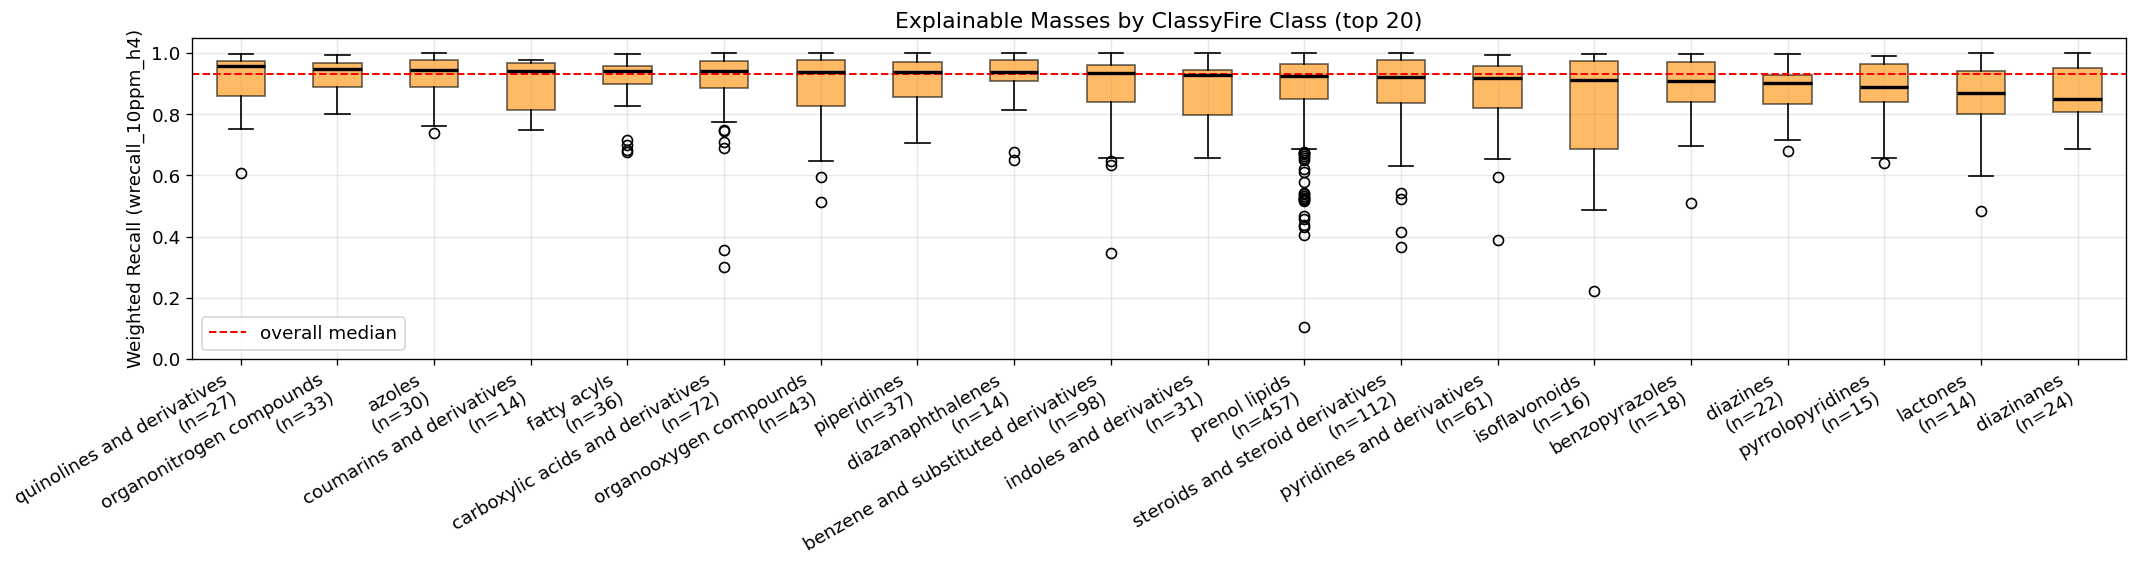

In [44]:
# --- Weighted recall by ClassyFire Class (top 20 by count) ---
top20_klass = frag_cf["klass"].value_counts().head(20).index.tolist()
df_klass_fr = frag_cf[frag_cf["klass"].isin(top20_klass)].dropna(subset=["klass"])

klass_order = (
    df_klass_fr.groupby("klass")[WRECALL_COL]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

klass_stats = (
    df_klass_fr.groupby("klass")[WRECALL_COL]
    .agg(["median", "mean", "count"])
    .reindex(klass_order)
    .round(3)
)
klass_stats.columns = ["median_wrecall", "mean_wrecall", "n_mols"]
print("Weighted recall by class (top 20):")
print(klass_stats.to_string())

groups_klass = [df_klass_fr[df_klass_fr["klass"] == k][WRECALL_COL].dropna().values for k in klass_order]
labels_klass = [f"{k}\n(n={len(g)})" for k, g in zip(klass_order, groups_klass)]

fig, ax = plt.subplots(figsize=(18, 5))
bp = ax.boxplot(groups_klass, labels=labels_klass, patch_artist=True, medianprops=dict(color="black", linewidth=2))
for patch in bp["boxes"]:
    patch.set_facecolor("darkorange")
    patch.set_alpha(0.6)
ax.axhline(frag_cf[WRECALL_COL].median(), color="red", linestyle="--", linewidth=1.2, label="overall median")
ax.set_ylabel(f"Weighted Recall ({WRECALL_COL})")
ax.set_title("Explainable Masses by ClassyFire Class (top 20)")
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

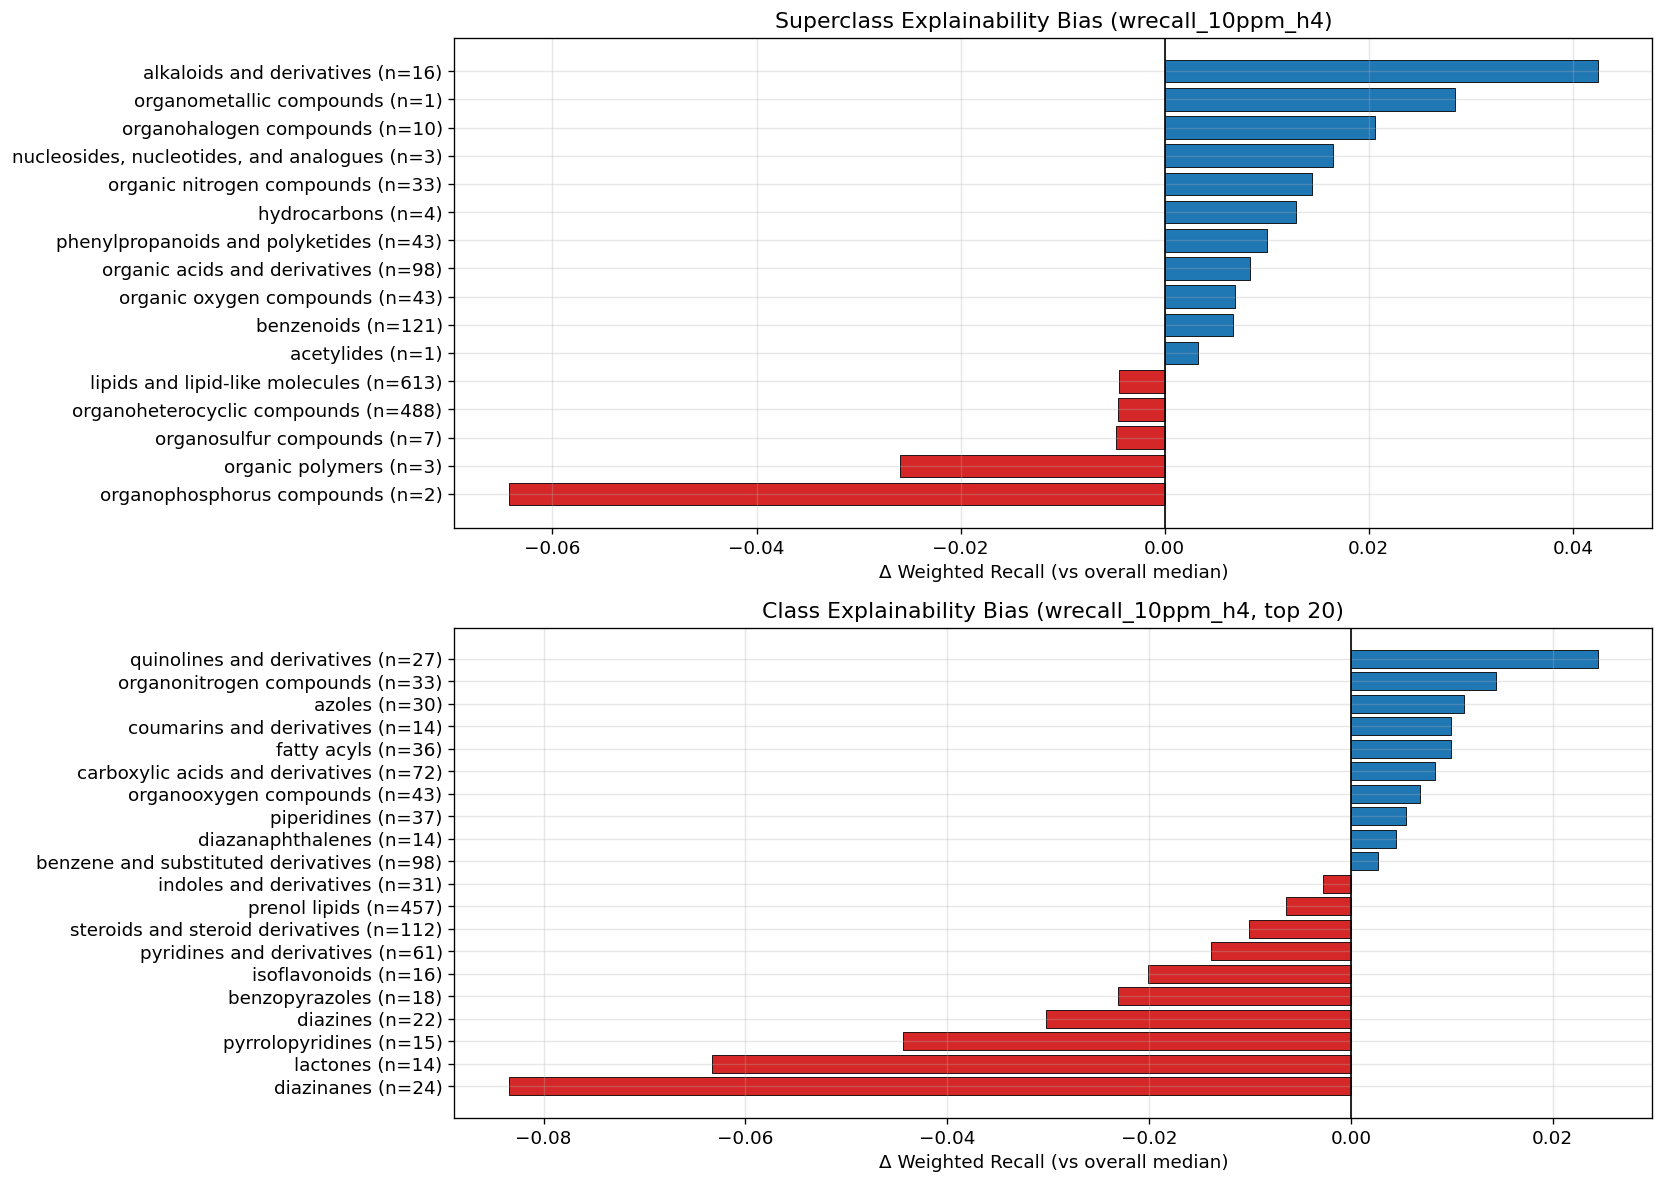


Overall median wrecall_10ppm_h4 = 0.932

Lowest-explainability superclasses:
                                 med_wrecall   bias  count
superklass                                                
organophosphorus compounds             0.868 -0.064      2
organic polymers                       0.906 -0.026      3
organosulfur compounds                 0.927 -0.005      7
organoheterocyclic compounds           0.927 -0.005    488
lipids and lipid-like molecules        0.927 -0.004    613

Lowest-explainability classes (top-20 by count):
                                  med_wrecall   bias  count
klass                                                      
diazinanes                              0.848 -0.083     24
lactones                                0.868 -0.063     14
pyrrolopyridines                        0.887 -0.044     15
diazines                                0.902 -0.030     22
benzopyrazoles                          0.909 -0.023     18
isoflavonoids                          

In [45]:
# --- Bias plot: deviation from overall median, by superclass and class ---
overall_median = frag_cf[WRECALL_COL].median()

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Superclass bias
bias_super = (
    df_super.groupby("superklass")[WRECALL_COL]
    .agg(["median", "count"])
    .rename(columns={"median": "med_wrecall"})
)
bias_super["bias"] = bias_super["med_wrecall"] - overall_median
bias_super = bias_super.sort_values("bias", ascending=True)
colors_super = ["#d62728" if b < 0 else "#1f77b4" for b in bias_super["bias"]]
axes[0].barh(
    [f"{s} (n={n})" for s, n in zip(bias_super.index, bias_super["count"])],
    bias_super["bias"],
    color=colors_super,
    edgecolor="black",
    linewidth=0.5,
)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("Δ Weighted Recall (vs overall median)")
axes[0].set_title(f"Superclass Explainability Bias ({WRECALL_COL})")

# Class bias (top 20)
bias_klass = (
    df_klass_fr.groupby("klass")[WRECALL_COL]
    .agg(["median", "count"])
    .rename(columns={"median": "med_wrecall"})
)
bias_klass["bias"] = bias_klass["med_wrecall"] - overall_median
bias_klass = bias_klass.sort_values("bias", ascending=True)
colors_klass = ["#d62728" if b < 0 else "#1f77b4" for b in bias_klass["bias"]]
axes[1].barh(
    [f"{k} (n={n})" for k, n in zip(bias_klass.index, bias_klass["count"])],
    bias_klass["bias"],
    color=colors_klass,
    edgecolor="black",
    linewidth=0.5,
)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("Δ Weighted Recall (vs overall median)")
axes[1].set_title(f"Class Explainability Bias ({WRECALL_COL}, top 20)")

plt.tight_layout()
plt.show()

print(f"\nOverall median {WRECALL_COL} = {overall_median:.3f}")
print("\nLowest-explainability superclasses:")
print(bias_super.head(5)[["med_wrecall", "bias", "count"]].round(3).to_string())
print("\nLowest-explainability classes (top-20 by count):")
print(bias_klass.head(8)[["med_wrecall", "bias", "count"]].round(3).to_string())

In [46]:
del frag_cf, cf_df
gc.collect()


34505

## 2. Explainable Masses by Chemical Class (CE-Controlled)

Uses `spec_stats_df` from `data/frag/nps_nist23_d3/` (per-spectrum fragmentation DAG stats) joined
with `spec_df` for instrument/CE info and ClassyFire taxonomy.

**Metric – weighted recall (`wrecall_10ppm_h4`)**: fraction of total spectral peak intensity
whose *m/z* is ≤ 10 ppm from a formula mass in the fragmentation DAG (≤4 H-shifts allowed).

**CE control**: higher collision energies produce more/different fragment ions that the DAG
may not cover, inflating 'unexplained' intensity. To avoid confounding class effects with CE
effects, we compute **CE-adjusted wrecall** = residual after subtracting the per-instrument
CE-bin median. We also show raw wrecall stratified by low/mid/high CE tertile.

In [47]:
# ── Load data ────────────────────────────────────────────────────────────────
spec_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/spec_stats_df.pkl")

cf_df = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")

spec_meta = pd.read_pickle(DATA_ROOT / "proc/nist23/spec_df.pkl")[
    ["spec_id", "inst_type", "nce", "ace"]
]

WRECALL_COL = "wrecall_10ppm_h4"  # primary explainability metric

# Merge spec-level wrecall ← spec metadata ← ClassyFire
frag_spec = (
    spec_stats_df[["spec_id", "mol_id", WRECALL_COL]]
    .merge(spec_meta, on="spec_id", how="inner")
    .merge(cf_df[["mol_id", "superklass", "klass", "subklass"]], on="mol_id", how="left")
)

# ── Native CE per instrument (FT → NCE %, QTOF/IT → ACE eV) ─────────────────
_CE_COL = {"FT": "nce", "QTOF": "ace", "IT": "nce"}
frag_spec["native_ce"] = np.nan
for _inst, _col in _CE_COL.items():
    _m = frag_spec["inst_type"] == _inst
    frag_spec.loc[_m, "native_ce"] = frag_spec.loc[_m, _col]

# ── CE tertile bins per instrument ───────────────────────────────────────────
frag_spec["ce_bin"] = frag_spec.groupby("inst_type", observed=True)["native_ce"].transform(
    lambda x: pd.qcut(x.rank(method="first"), q=3, labels=["low", "mid", "high"])
)

# ── CE-adjusted wrecall (residual) ───────────────────────────────────────────
# Subtract per-(inst_type, ce_bin) median to isolate molecular-class effect
bin_medians = frag_spec.groupby(["inst_type", "ce_bin"], observed=True)[WRECALL_COL].transform("median")
frag_spec["wrecall_adj"] = frag_spec[WRECALL_COL] - bin_medians

print(f"Spectra: {len(frag_spec):,}  |  CF coverage: {frag_spec['superklass'].notna().mean():.1%}")
print(f"Overall median wrecall: {frag_spec[WRECALL_COL].median():.3f}")
print("\nCE bins (FT = NCE%, QTOF = ACE eV):")
print(
    frag_spec.groupby(["inst_type", "ce_bin"], observed=True)["native_ce"]
    .agg(["min", "max", "count"])
    .to_string()
)

del spec_stats_df
gc.collect()

Spectra: 27,831  |  CF coverage: 100.0%
Overall median wrecall: 0.987

CE bins (FT = NCE%, QTOF = ACE eV):
                   min    max  count
inst_type ce_bin                    
FT        low      2.0   35.0   8731
          mid     35.0   65.0   8730
          high    65.0  195.0   8731
QTOF      low      2.0   15.0    546
          mid     15.0   27.0    546
          high    27.0   45.0    547


0

In [48]:
# ── CE-adjusted wrecall by Superclass ────────────────────────────────────────
df_s = frag_spec.dropna(subset=["superklass"])

super_adj = (
    df_s.groupby("superklass")[[WRECALL_COL, "wrecall_adj"]]
    .agg("median")
    .rename(columns={WRECALL_COL: "med_raw", "wrecall_adj": "med_adj"})
    .join(df_s.groupby("superklass")[WRECALL_COL].count().rename("n_specs"))
    .sort_values("med_adj")
    .round(3)
)
print(f"Superclass — raw vs CE-adjusted median wrecall (sorted by adj, low=harder):")
print(super_adj.to_string())

Superclass — raw vs CE-adjusted median wrecall (sorted by adj, low=harder):
                                         med_raw  med_adj  n_specs
superklass                                                        
organic polymers                           0.949   -0.036       56
organosulfur compounds                     0.954   -0.034      103
acetylides                                 0.966   -0.020       16
organophosphorus compounds                 0.966   -0.018       43
hydrocarbons                               0.975   -0.013       74
organometallic compounds                   0.982   -0.005       14
organic oxygen compounds                   0.985   -0.002      796
lipids and lipid-like molecules            0.986   -0.001    11895
organoheterocyclic compounds               0.988    0.000     9115
phenylpropanoids and polyketides           0.988    0.001      883
benzenoids                                 0.989    0.001     2032
alkaloids and derivatives                  0.997    0

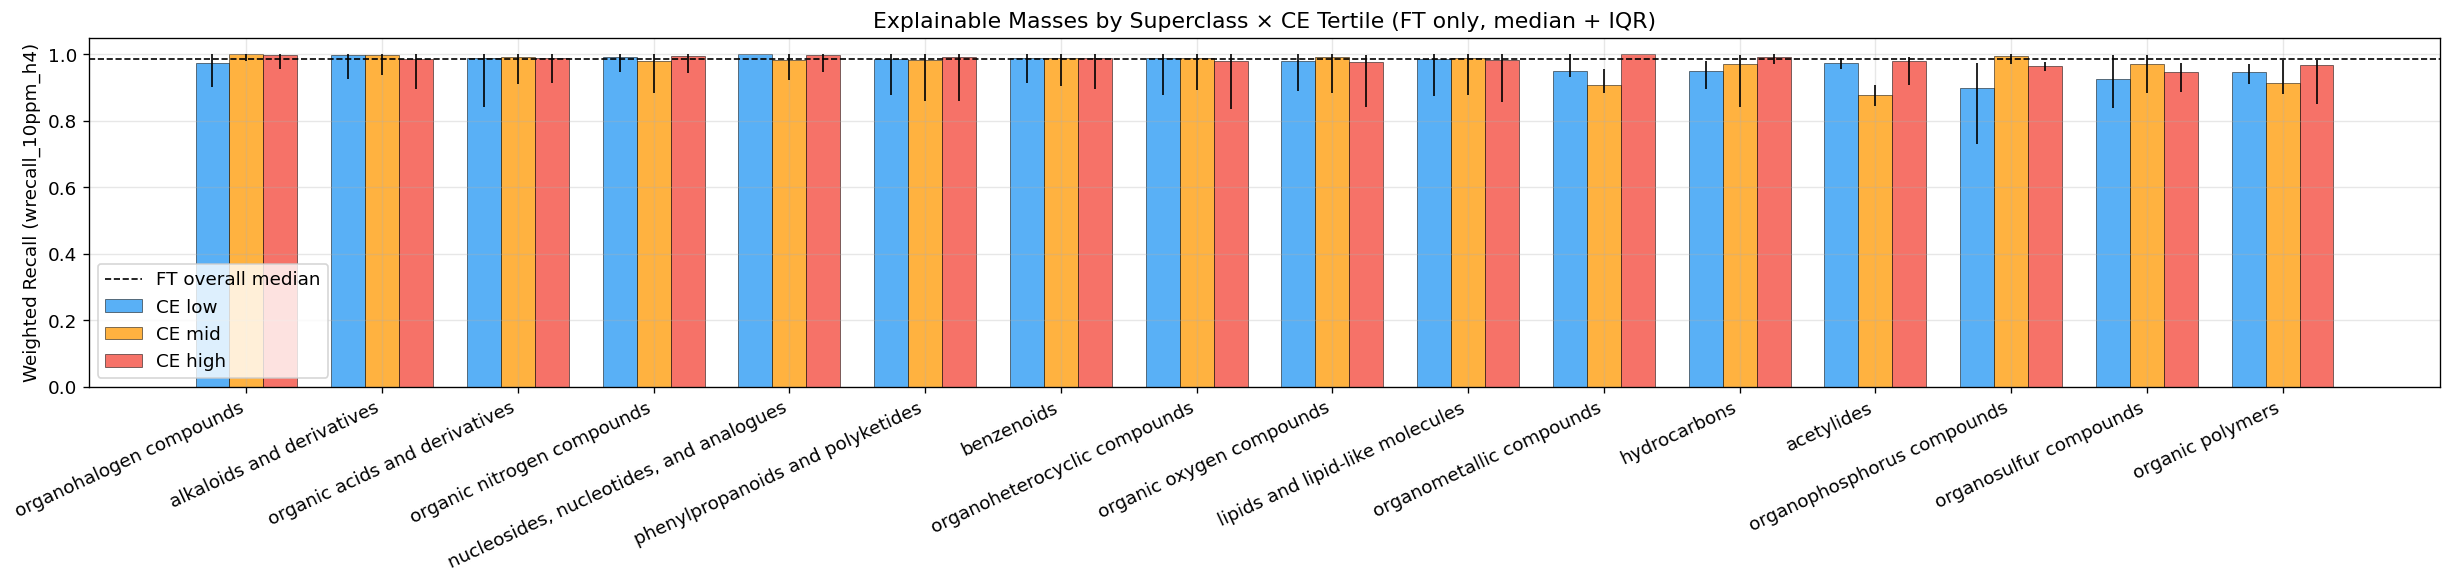

In [49]:
# ── Bar chart: raw wrecall by Superclass × CE tertile (FT only) ─────────────
df_ft = frag_spec[(frag_spec["inst_type"] == "FT") & frag_spec["superklass"].notna()].copy()

CE_COLORS = {"low": "#2196F3", "mid": "#FF9800", "high": "#F44336"}
super_order_ft = (
    df_ft.groupby("superklass")[WRECALL_COL].median().sort_values(ascending=False).index.tolist()
)

fig, ax = plt.subplots(figsize=(max(14, len(super_order_ft) * 1.3), 5))
width = 0.25
x = np.arange(len(super_order_ft))

for i, ce_lbl in enumerate(["low", "mid", "high"]):
    medians, q1s, q3s = [], [], []
    for s in super_order_ft:
        vals = df_ft[(df_ft["superklass"] == s) & (df_ft["ce_bin"] == ce_lbl)][WRECALL_COL].dropna()
        medians.append(vals.median() if len(vals) else np.nan)
        q1s.append(vals.quantile(0.25) if len(vals) else np.nan)
        q3s.append(vals.quantile(0.75) if len(vals) else np.nan)
    medians, q1s, q3s = np.array(medians), np.array(q1s), np.array(q3s)
    ax.bar(x + i * width, medians, width=width, label=f"CE {ce_lbl}",
           color=CE_COLORS[ce_lbl], alpha=0.75, edgecolor="black", linewidth=0.4)
    ax.vlines(x + i * width, q1s, q3s, color="black", linewidth=1.0)

ax.axhline(df_ft[WRECALL_COL].median(), color="black", linestyle="--", linewidth=1, label="FT overall median")
ax.set_xticks(x + width)
ax.set_xticklabels(super_order_ft, rotation=25, ha="right")
ax.set_ylabel(f"Weighted Recall ({WRECALL_COL})")
ax.set_title(f"Explainable Masses by Superclass × CE Tertile (FT only, median + IQR)")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

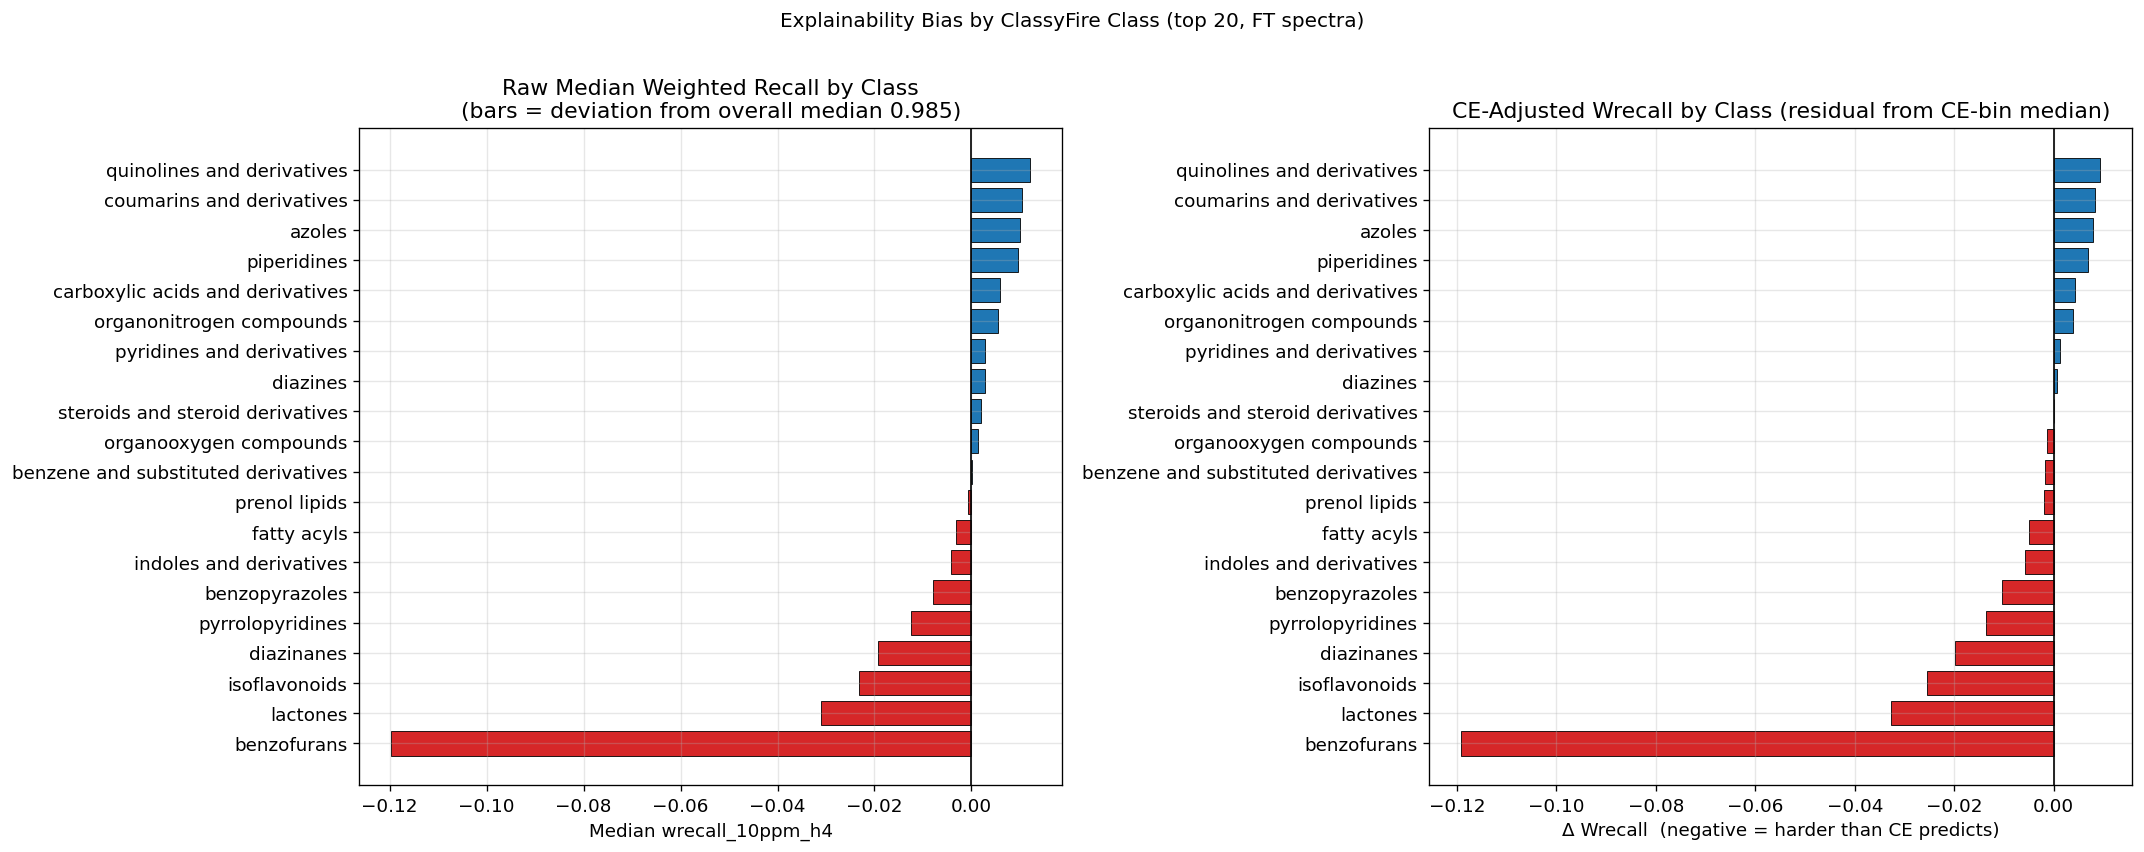

Class explainability (FT, CE-adjusted, sorted by adj):
                                     med_raw  med_adj  n_specs
klass                                                         
benzofurans                            0.865   -0.119      309
lactones                               0.954   -0.033      270
isoflavonoids                          0.962   -0.025      279
diazinanes                             0.965   -0.020      394
pyrrolopyridines                       0.972   -0.014      264
benzopyrazoles                         0.977   -0.010      272
indoles and derivatives                0.981   -0.006      515
fatty acyls                            0.982   -0.005      551
prenol lipids                          0.984   -0.002     8453
benzene and substituted derivatives    0.985   -0.002     1557
organooxygen compounds                 0.986   -0.001      732
steroids and steroid derivatives       0.987    0.000     2136
diazines                               0.987    0.001      337


In [50]:
# ── CE-adjusted bias by Class (top 20) ──────────────────────────────────────
top20_klass = frag_spec["klass"].value_counts().head(20).index.tolist()
df_ft_klass = frag_spec[
    (frag_spec["inst_type"] == "FT") & frag_spec["klass"].isin(top20_klass)
].dropna(subset=["klass"])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (col, title, xlabel) in zip(axes, [
    (WRECALL_COL,
     "Raw Median Weighted Recall by Class",
     f"Median {WRECALL_COL}"),
    ("wrecall_adj",
     "CE-Adjusted Wrecall by Class (residual from CE-bin median)",
     "Δ Wrecall  (negative = harder than CE predicts)"),
]):
    vals = df_ft_klass.groupby("klass")[col].median().sort_values(ascending=True)
    ref = df_ft_klass[WRECALL_COL].median() if col == WRECALL_COL else 0.0
    colors = ["#d62728" if v < ref else "#1f77b4" for v in vals]
    bar_vals = vals.values - ref if col == WRECALL_COL else vals.values
    ax.barh(vals.index, bar_vals, color=colors, edgecolor="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=1)
    if col == WRECALL_COL:
        ax.set_title(f"{title}\n(bars = deviation from overall median {ref:.3f})")
    else:
        ax.set_title(title)
    ax.set_xlabel(xlabel)

plt.suptitle("Explainability Bias by ClassyFire Class (top 20, FT spectra)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

# Print summary table
klass_summary = (
    df_ft_klass.groupby("klass")[[WRECALL_COL, "wrecall_adj"]]
    .agg("median")
    .rename(columns={WRECALL_COL: "med_raw", "wrecall_adj": "med_adj"})
    .join(df_ft_klass.groupby("klass")[WRECALL_COL].count().rename("n_specs"))
    .sort_values("med_adj")
    .round(3)
)
print("Class explainability (FT, CE-adjusted, sorted by adj):")
print(klass_summary.to_string())

In [51]:
del frag_spec
gc.collect()


17484

## 3. H-Shift Sensitivity: Comparing wrecall_10ppm_h1 → h4

How much does relaxing the H-shift tolerance (h1 → h4) improve DAG coverage?
Each step allows one additional H-shift when matching formula masses to observed peaks.

- **h1**: ≤1 H-shift allowed
- **h2**: ≤2 H-shifts allowed
- **h3**: ≤3 H-shifts allowed
- **h4**: ≤4 H-shifts allowed

In [ ]:
# ── Load mol-level stats for all four h-shift variants ───────────────────────
H_COLS = ["wrecall_10ppm_h1", "wrecall_10ppm_h2", "wrecall_10ppm_h3", "wrecall_10ppm_h4"]
H_LABELS = ["h1", "h2", "h3", "h4"]
H_COLORS = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759"]

mol_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/mol_stats_df.pkl")
cf_df = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")
cf_cols = ["mol_id", "kingdom", "superklass", "klass", "subklass"]

hcf = mol_stats_df.merge(cf_df[cf_cols], on="mol_id", how="left")
del mol_stats_df
gc.collect()

# ── Overall distribution (box plots) ─────────────────────────────────────────
print("Overall mol-level wrecall_10ppm stats:")
print(hcf[H_COLS].describe().round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot(
    [hcf[c].dropna().values for c in H_COLS],
    labels=H_LABELS,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
)
for patch, color in zip(bp["boxes"], H_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xlabel("H-shift tolerance")
ax.set_ylabel("Weighted Recall (10 ppm)")
ax.set_title("Overall wrecall_10ppm: h1 → h4 (mol-level)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

# ── Incremental gain table ────────────────────────────────────────────────────
gain = pd.DataFrame({"metric": H_COLS, "median": [hcf[c].median() for c in H_COLS]})
gain["gain_vs_prev"] = gain["median"].diff().round(4)
print("\nMedian wrecall and incremental gain per H-shift step:")
print(gain.to_string(index=False))

In [ ]:
# ── Spec-level h-shift comparison (FT, overall distribution) ─────────────────
spec_stats_df = pd.read_pickle(DATA_ROOT / "frag/nps_nist23_d3/spec_stats_df.pkl")
cf_df2 = pd.read_pickle(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl")
spec_meta = pd.read_pickle(DATA_ROOT / "proc/nist23/spec_df.pkl")[
    ["spec_id", "inst_type", "nce", "ace"]
]

hspec = (
    spec_stats_df[["spec_id", "mol_id"] + H_COLS]
    .merge(spec_meta, on="spec_id", how="inner")
    .merge(cf_df2[["mol_id", "superklass"]], on="mol_id", how="left")
)
del spec_stats_df, cf_df2
gc.collect()

hspec_ft = hspec[hspec["inst_type"] == "FT"]

print("Spec-level (FT) wrecall_10ppm stats:")
print(hspec_ft[H_COLS].describe().round(3).to_string())

# ── Box plots: spec-level FT ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot(
    [hspec_ft[c].dropna().values for c in H_COLS],
    labels=H_LABELS,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
)
for patch, color in zip(bp["boxes"], H_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xlabel("H-shift tolerance")
ax.set_ylabel("Weighted Recall (10 ppm)")
ax.set_title("wrecall_10ppm h1 → h4 (FT spectra)")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

# ── Spec-level superclass comparison (line plot) ──────────────────────────────
df_hs = hspec_ft.dropna(subset=["superklass"])
super_order_s = (
    df_hs.groupby("superklass")["wrecall_10ppm_h4"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)
spec_super_med = (
    df_hs.groupby("superklass")[H_COLS]
    .median()
    .reindex(super_order_s)
    .round(3)
)

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(super_order_s))
for col, lbl, color in zip(H_COLS, H_LABELS, H_COLORS):
    ax.plot(x, spec_super_med[col].values, marker="o", label=lbl, color=color, linewidth=1.5, markersize=5)
ax.set_xticks(x)
ax.set_xticklabels(super_order_s, rotation=25, ha="right")
ax.set_ylabel("Median Weighted Recall (10 ppm, FT)")
ax.set_title("H-Shift Comparison by ClassyFire Superclass (FT spectra, sorted by h4)")
ax.set_ylim(0, 1.05)
ax.legend(title="H-shift")
plt.tight_layout()
plt.show()

del hspec
gc.collect()

In [ ]:
# ── Median wrecall by Superclass × H-shift (grouped bar) ─────────────────────
df_h = hcf.dropna(subset=["superklass"])

# Sort superclasses by h4 median descending
super_order_h = (
    df_h.groupby("superklass")["wrecall_10ppm_h4"]
    .median()
    .sort_values(ascending=True)
    .index.tolist()
)

super_medians = (
    df_h.groupby("superklass")[H_COLS]
    .median()
    .reindex(super_order_h)
    .round(3)
)

fig, ax = plt.subplots(figsize=(14, max(5, len(super_order_h) * 0.55)))
y = np.arange(len(super_order_h))
bar_height = 0.18

for i, (col, lbl, color) in enumerate(zip(H_COLS, H_LABELS, H_COLORS)):
    ax.barh(
        y + (i - 1.5) * bar_height,
        super_medians[col].values,
        height=bar_height,
        label=lbl,
        color=color,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.3,
    )

ax.set_yticks(y)
ax.set_yticklabels(super_order_h)
ax.set_xlabel("Median Weighted Recall (10 ppm)")
ax.set_title("H-Shift Comparison by ClassyFire Superclass (mol-level, sorted by h4)")
ax.set_xlim(0, 1.05)
ax.legend(title="H-shift", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
summary = super_medians.copy()
summary.columns = H_LABELS
summary["gain_h1→h4"] = (summary["h4"] - summary["h1"]).round(3)
print("Median wrecall by superclass (sorted by h4 asc):")
print(summary.to_string())

In [ ]:
# ── Worst-case analysis: low-wrecall tail across h-shifts ────────────────────
# Threshold below which a molecule/spectrum is considered 'hard to explain'
THRESHOLDS = [0.5, 0.7, 0.9]

# ── Mol-level: fraction below threshold per h-shift ──────────────────────────
print("Fraction of molecules below wrecall threshold (mol-level):")
frac_df = pd.DataFrame(
    {f"<{t}": [(hcf[c] < t).mean().round(3) for c in H_COLS] for t in THRESHOLDS},
    index=H_LABELS,
)
print(frac_df.to_string())

# ── Mol-level: 10th percentile (worst-case) per superclass ───────────────────
df_h = hcf.dropna(subset=["superklass"])
super_p10 = (
    df_h.groupby("superklass")[H_COLS]
    .quantile(0.10)
    .round(3)
)
super_p10.columns = H_LABELS
super_p10["gain_h1→h4"] = (super_p10["h4"] - super_p10["h1"]).round(3)
super_p10 = super_p10.sort_values("h4", ascending=True)
print("\n10th-percentile (worst-case) wrecall by superclass:")
print(super_p10.to_string())

# ── Plot: p10 grouped bars by superclass ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, max(5, len(super_p10) * 0.55)))
y = np.arange(len(super_p10))
bar_height = 0.18
for i, (lbl, color) in enumerate(zip(H_LABELS, H_COLORS)):
    ax.barh(
        y + (i - 1.5) * bar_height,
        super_p10[lbl].values,
        height=bar_height,
        label=lbl,
        color=color,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.3,
    )
ax.set_yticks(y)
ax.set_yticklabels(super_p10.index)
ax.set_xlabel("10th-Percentile Weighted Recall (10 ppm)")
ax.set_title("Worst-Case (p10) wrecall by Superclass: h1 → h4 (mol-level, sorted by h4)")
ax.set_xlim(0, 1.05)
ax.legend(title="H-shift", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ── Hardest molecules: those with lowest h4 wrecall ──────────────────────────
print("\nHardest 20 molecules (lowest wrecall_10ppm_h4):")
hard_cols = ["mol_id", "superklass", "klass"] + H_COLS
hard_cols = [c for c in hard_cols if c in hcf.columns]
print(
    hcf.nsmallest(20, "wrecall_10ppm_h4")[hard_cols]
    .round(3)
    .to_string(index=False)
)

del df_h
gc.collect()